In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
import pandas as pd

df = pd.read_csv(r"C:\Users\hp\Downloads\archive (2)\Titanic-Dataset.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:

df.shape


(891, 12)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# TASK 2: Exploratory Data Analysis (EDA)

## 1. Questions Before Analysis

Before analyzing the Titanic dataset, the following questions were defined:

1. What percentage of passengers survived the Titanic disaster?
2. Did gender affect the survival rate of passengers?
3. Did passenger class affect the survival rate?
4. Does age have any relationship with passenger survival?
5. What is the distribution of passenger fares, and are there any unusual values or outliers?
6. Does the dataset contain missing values or duplicate records?

In [11]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [12]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 2. Understanding the Dataset Structure

The Titanic dataset contains 891 rows and 12 columns.

The dataset contains numerical as well as categorical variables.

### Numerical Variables
- PassengerId
- Survived
- Pclass
- Age
- SibSp
- Parch
- Fare

### Categorical Variables
- Name
- Sex
- Ticket
- Cabin
- Embarked

### Data Quality Observation

Missing values were identified in three columns:

- Age: 177 missing values
- Cabin: 687 missing values
- Embarked: 2 missing values

The remaining columns do not contain missing values.


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [15]:
df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

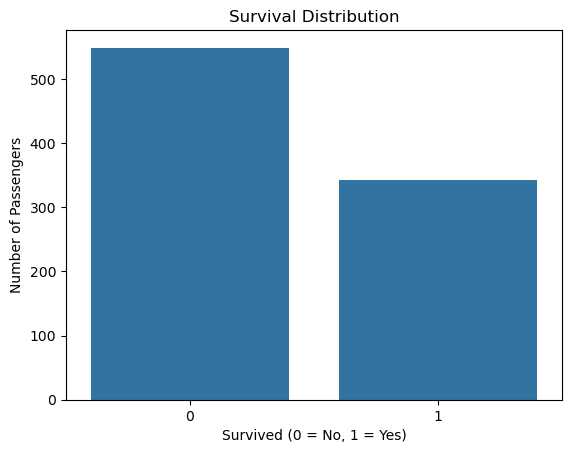

In [16]:
sns.countplot(x="Survived", data=df)
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

### Observation – Overall Survival

The analysis shows that 342 out of 891 passengers survived, resulting in a survival rate of approximately 38.38%.

In contrast, 549 passengers did not survive, representing approximately 61.62% of the passengers.

Therefore, the majority of passengers in the dataset did not survive the Titanic disaster.

In [17]:
pd.crosstab(df["Sex"], df["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [18]:
survival_by_gender = pd.crosstab(df["Sex"], df["Survived"], normalize="index") * 100
survival_by_gender

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


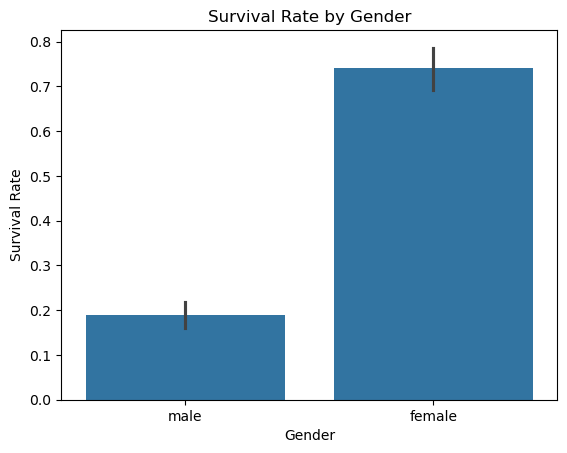

In [19]:
sns.barplot(x="Sex", y="Survived", data=df)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()

### Observation – Gender and Survival

The analysis shows a clear difference in survival rates between male and female passengers.

Approximately 74.2% of female passengers survived, whereas only about 18.9% of male passengers survived.

This indicates that gender had a strong association with survival in the Titanic dataset. Female passengers had a substantially higher survival rate than male passengers.

In [20]:
pd.crosstab(df["Pclass"], df["Survived"])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [21]:
pd.crosstab(df["Pclass"], df["Survived"], normalize="index") * 100

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


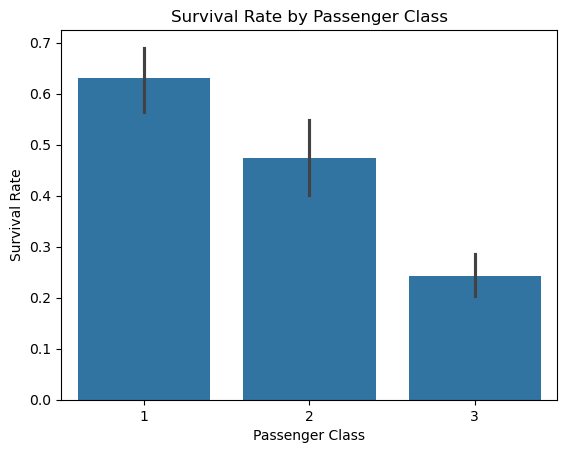

In [22]:
sns.barplot(x="Pclass", y="Survived", data=df)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

### Observation – Passenger Class and Survival

The analysis shows a clear relationship between passenger class and survival rate.

Passengers in 1st class had the highest survival rate of approximately 63%, followed by 2nd class passengers at approximately 47%. 3rd class passengers had the lowest survival rate at approximately 24%.

This indicates that passengers in higher classes had a higher survival rate compared with passengers in lower classes.

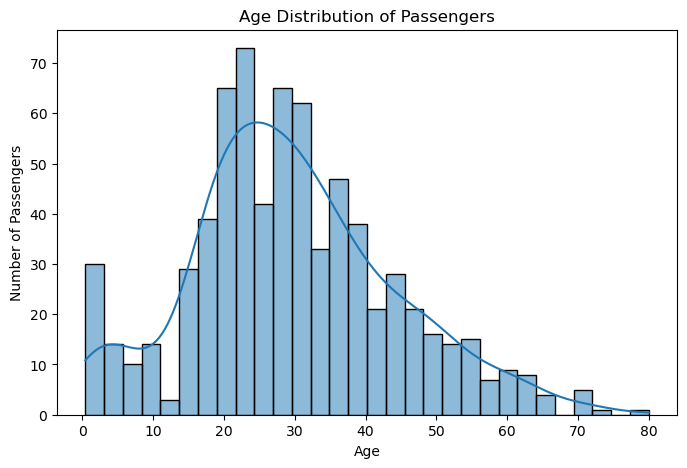

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

### Observation – Age Distribution

The age distribution shows that most passengers were between approximately 20 and 35 years old.

The distribution is right-skewed, with fewer passengers at older ages. The dataset contains passengers ranging from infants to approximately 80 years of age.

It should also be noted that 177 age values are missing, which may affect age-based analysis.

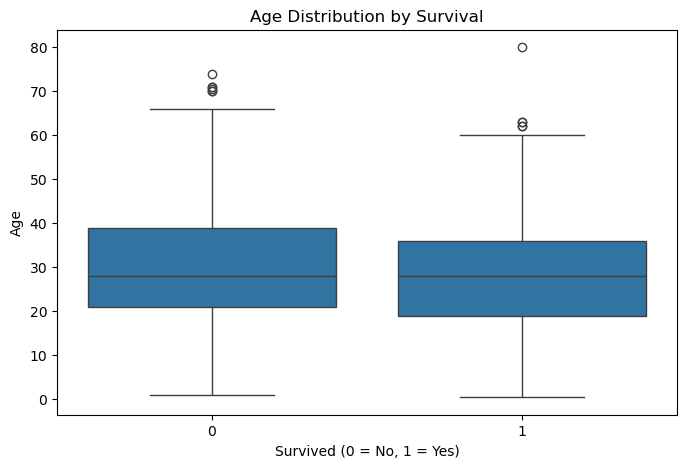

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

### Observation – Age and Survival

The boxplot shows that the median age of survivors and non-survivors was approximately similar, at around 28 years.

Both groups show a wide range of ages, with some extreme age observations visible as outliers.

Based on the visualization alone, there does not appear to be a very strong difference in the overall age distribution between survivors and non-survivors. A statistical test can be used later to further investigate the relationship between age and survival.

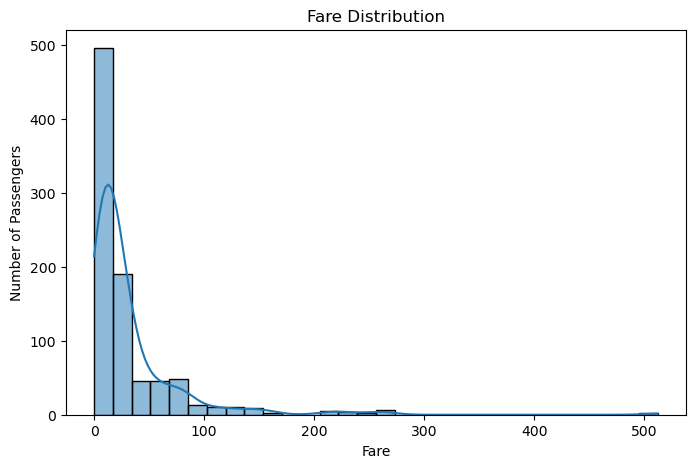

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="Fare", bins=30, kde=True)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

### Observation – Fare Distribution

The fare distribution is strongly right-skewed, indicating that most passengers paid relatively low fares while a smaller number of passengers paid substantially higher fares.

The long right tail suggests the presence of potential extreme or outlier fare values. These unusual values should be investigated further during the anomaly detection stage.

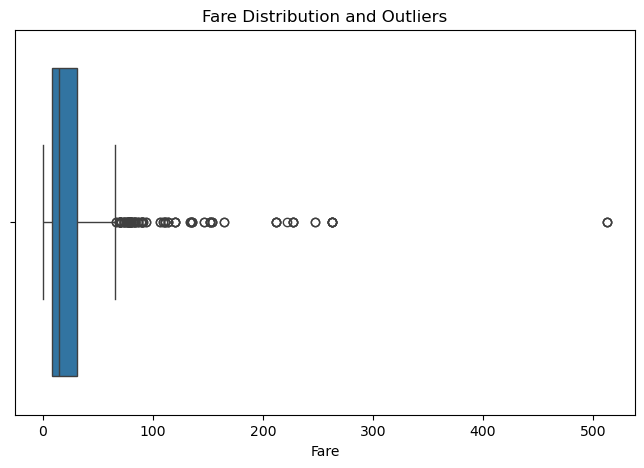

In [26]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Fare"])

plt.title("Fare Distribution and Outliers")
plt.xlabel("Fare")

plt.show()

### Observation – Fare Outliers

The boxplot shows a large number of potential outliers in the Fare variable.

Most fare values are concentrated in the lower range, while several passengers paid substantially higher fares. One particularly extreme fare value is around 512.

These values should be treated as potential outliers rather than automatically removing them, because they may represent genuine high-cost tickets or group bookings.

In [27]:
df["Fare"].sort_values(ascending=False).head(10)

258    512.3292
737    512.3292
679    512.3292
88     263.0000
27     263.0000
341    263.0000
438    263.0000
311    262.3750
742    262.3750
118    247.5208
Name: Fare, dtype: float64

In [28]:
df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [29]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Fare"] < lower_bound) | (df["Fare"] > upper_bound)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Lower Bound: -26.724
Upper Bound: 65.6344
Number of Outliers: 116


### Observation – Fare Distribution and Outliers

The Fare variable is strongly right-skewed. The mean fare is 32.20, while the median fare is only 14.45, indicating that some high fare values are pulling the average upward.

The minimum fare is 0 and the maximum fare is 512.33. The boxplot also shows several potential outliers, including extremely high fare values around 512.

Using the IQR method, fares above the upper outlier boundary can be identified as potential outliers. These values should not be automatically removed because they may represent genuine high-cost tickets or group bookings.

In [31]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Percentage
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


In [32]:
df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

### Observation – Fare Distribution and Outliers

The Fare variable is strongly right-skewed. The mean fare (32.20) is considerably higher than the median fare (14.45), indicating the influence of higher fare values.

Using the IQR method, the upper outlier boundary was calculated as 65.63. A total of 116 observations were identified as potential outliers.

The highest fare in the dataset is 512.33. These potential outliers should not be automatically removed because they may represent genuine high-cost tickets or group bookings.

In [34]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Sex"], df["Survived"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 260.71702016732104
P-value: 1.1973570627755645e-58
Degrees of Freedom: 1


## 7. Hypothesis Testing – Gender and Survival

### Hypotheses

**Null Hypothesis (H₀):** There is no significant association between gender and survival.

**Alternative Hypothesis (H₁):** There is a significant association between gender and survival.

A Chi-Square Test of Independence was performed because both variables are categorical.

### Results

- Chi-Square Statistic: 260.717
- Degrees of Freedom: 1
- P-value: 1.197 × 10⁻⁵⁸
- Significance Level: 0.05

### Conclusion

Since the p-value is much smaller than 0.05, the null hypothesis is rejected.

Therefore, there is a statistically significant association between gender and survival in the Titanic dataset.

The statistical result is also supported by the visualization, which shows that female passengers had a substantially higher survival rate than male passengers.

In [35]:
table_class = pd.crosstab(df["Pclass"], df["Survived"])

chi2, p_value, dof, expected = chi2_contingency(table_class)

print("Contingency Table:")
print(table_class)

print("\nChi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Contingency Table:
Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119

Chi-Square Statistic: 102.88898875696056
P-value: 4.549251711298793e-23
Degrees of Freedom: 2


## 8. Hypothesis Testing – Passenger Class and Survival

### Hypotheses

**Null Hypothesis (H₀):** There is no significant association between passenger class and survival.

**Alternative Hypothesis (H₁):** There is a significant association between passenger class and survival.

A Chi-Square Test of Independence was performed because both passenger class and survival are categorical variables.

### Results

- Chi-Square Statistic: 102.889
- Degrees of Freedom: 2
- P-value: 4.549 × 10⁻²³
- Significance Level: 0.05

### Conclusion

Since the p-value is much smaller than 0.05, the null hypothesis is rejected.

Therefore, there is a statistically significant association between passenger class and survival in the Titanic dataset.

The result is also supported by the visualization, which shows that 1st class passengers had the highest survival rate, while 3rd class passengers had the lowest survival rate.

In [36]:
from scipy.stats import mannwhitneyu

survived_age = df[df["Survived"] == 1]["Age"].dropna()
not_survived_age = df[df["Survived"] == 0]["Age"].dropna()

statistic, p_value = mannwhitneyu(
    survived_age,
    not_survived_age,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U Statistic: 57682.0
P-value: 0.16049252477737763


## 9. Hypothesis Testing – Age and Survival

### Hypotheses

**Null Hypothesis (H₀):** There is no significant difference in the age distributions of survivors and non-survivors.

**Alternative Hypothesis (H₁):** There is a significant difference in the age distributions of survivors and non-survivors.

A Mann-Whitney U test was performed to compare the age distributions of survivors and non-survivors.

### Results

- Mann-Whitney U Statistic: 57,682
- P-value: 0.1605
- Significance Level: 0.05

### Conclusion

Since the p-value (0.1605) is greater than 0.05, the null hypothesis is not rejected.

Therefore, the analysis does not provide sufficient statistical evidence of a significant difference in age distributions between survivors and non-survivors.

This result is consistent with the boxplot, which showed similar median ages for the two groups.

## 10. Key Findings

The exploratory data analysis of the Titanic dataset revealed the following key findings:

1. Out of 891 passengers, 342 survived, giving an overall survival rate of approximately 38.38%.

2. Gender showed a strong association with survival. Approximately 74.2% of female passengers survived, compared with approximately 18.9% of male passengers.

3. Passenger class was also significantly associated with survival. The survival rate was approximately 63% for 1st class, 47% for 2nd class, and 24% for 3rd class.

4. The age distribution was concentrated mainly around 20–35 years. Statistical testing did not find a significant difference in age distributions between survivors and non-survivors (p = 0.1605).

5. Fare was strongly right-skewed. The mean fare was 32.20, while the median was 14.45. The IQR method identified 116 potential fare outliers.

6. The dataset contains missing values, particularly in the Cabin variable, where approximately 77.10% of values are missing.

7. No duplicate rows were identified in the dataset.

## 11. Data Quality Issues

The following data-quality issues were identified during the exploratory analysis:

### 1. Missing Values

The dataset contains missing values in three variables:

- **Age:** 177 missing values (19.87%)
- **Cabin:** 687 missing values (77.10%)
- **Embarked:** 2 missing values (0.22%)

The Cabin variable has a particularly high percentage of missing values and may require special treatment in further analysis.

### 2. Potential Outliers

The Fare variable contains potential outliers. Using the IQR method, the upper outlier boundary was calculated as 65.63, resulting in 116 potential outlier observations.

These values should be investigated rather than automatically removed because they may represent genuine high-cost tickets.

### 3. Duplicate Records

No duplicate rows were found in the dataset.

### 4. Data Type Considerations

PassengerId is stored as an integer but functions as an identifier rather than a numerical measurement. Similarly, Survived and Pclass are numerical in storage but can also be treated as categorical variables during analysis.

## 12. Conclusion

The Exploratory Data Analysis of the Titanic dataset revealed several important patterns and data-quality issues.

The overall survival rate was approximately 38.38%. Gender and passenger class showed strong and statistically significant associations with survival. Female passengers had a substantially higher survival rate than male passengers, while passengers in higher classes generally had higher survival rates.

The analysis of age did not provide sufficient statistical evidence of a significant difference in age distributions between survivors and non-survivors.

The Fare variable was strongly right-skewed and contained 116 potential outliers based on the IQR method. The dataset also contained a significant number of missing values, particularly in the Cabin variable.

Overall, the analysis demonstrates that gender and passenger class were important factors associated with survival in this dataset. Before further analysis or predictive modeling, missing values and potential outliers should be carefully investigated and appropriately handled.